In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from torchinfo import summary
import random
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from scipy.stats import qmc
from matplotlib.ticker import LogLocator
# import optuna
from torchinfo import summary

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cuda":
    # Explicitly initialize the CUDA context
    torch.cuda.init()

    # Force a small CUDA operation
    _ = torch.empty(1, device=device)
    torch.cuda.synchronize()

    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(1000, 1000, device="cuda",
                    requires_grad=True)

    loss = (x @ x.T).mean()
    loss.backward()

    torch.cuda.synchronize()

    print("CUDA forward/backward test passed.")
    
def lhs_timespace(N, x_min, x_max, t_min, t_max):
    sampler = qmc.LatinHypercube(d=2)
    sample = sampler.random(N)

    sample[:, 0] = x_min + (x_max - x_min) * sample[:, 0]
    sample[:, 1] = t_min + (t_max - t_min) * sample[:, 1]

    x = torch.tensor(sample[:, 0:1], dtype=torch.float32, device=device)
    t = torch.tensor(sample[:, 1:2], dtype=torch.float32, device=device)

    return x, t

GPU: NVIDIA RTX A2000
PyTorch: 2.5.1
CUDA available: True
CUDA version: 12.1
GPU: NVIDIA RTX A2000
CUDA forward/backward test passed.


In [2]:
%%time

# =========================================================
# Reproducibility
# =========================================================
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =========================================================
# Physical parameters
# =========================================================
k = 0.1
Q = 1.0
lambda_PDE = 0.1

softplus = nn.Softplus(1.0)

# Domain
x_min, x_max = -0.5, 0.5
t_min, t_max = 0.0, 1.0
x_star = 0.0

# =========================================================
# PINN architecture
# =========================================================
class PINN(nn.Module):

    def __init__(self, hidden_layers, hidden_units):
        super().__init__()

        layers = []

        # Input layer
        layers.append(nn.Linear(2, hidden_units))
        layers.append(nn.Tanh())

        # Hidden layers
        for _ in range(hidden_layers - 1):
            layers.append(nn.Linear(hidden_units, hidden_units))
            layers.append(nn.Tanh())

        # Output layer
        layers.append(nn.Linear(hidden_units, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        xt = torch.cat([x, t], dim=1)
        return self.net(xt)


# =========================================================
# Parameter-count function
# =========================================================
def count_parameters(hidden_layers, hidden_units):

    # Input layer: 2 -> H
    n_params = 2 * hidden_units + hidden_units

    # H -> H hidden layers
    for _ in range(hidden_layers - 1):
        n_params += hidden_units * hidden_units + hidden_units

    # Output layer: H -> 1
    n_params += hidden_units + 1

    return n_params


# =========================================================
# PDE residual
# =========================================================
def pde_residual(x, t, k, model):

    x = x.requires_grad_(True)
    t = t.requires_grad_(True)

    u = model(x, t)

    u_x = torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_t = torch.autograd.grad(
        u,
        t,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    return u_t - k * u_xx


# =========================================================
# Loss
# =========================================================
def compute_loss(
    x_pde, t_pde,
    x_ic, t_ic, u_ic_true,
    x_bc_l, t_bc_l, u_bc_l_true,
    x_bc_r, t_bc_r, u_bc_r_true,
    x_delta, t_delta,
    k, model,
    lambda_PDE
):

    pde_res = pde_residual(
        x_pde, t_pde, k, model
    )

    delta_res = pde_residual(
        x_delta, t_delta, k, model
    )

    lpde1 = torch.mean(pde_res**2)

    lpde1_med = torch.median(pde_res**2)

    lpde2 = -2.0 * torch.mean(delta_res * Q)

    loss_pde = lpde1 + lpde2

    loss_ic = torch.mean((model(x_ic, t_ic) - u_ic_true)**2)

    loss_bc_l = torch.mean((model(x_bc_l, t_bc_l) - u_bc_l_true)**2)

    loss_bc_r = torch.mean((model(x_bc_r, t_bc_r) - u_bc_r_true)**2)

    total_loss = (lambda_PDE * loss_pde + loss_ic + loss_bc_l + loss_bc_r)

    return (total_loss, lpde1, lpde1_med, lpde2, loss_ic, loss_bc_l, loss_bc_r)



# =========================================================
# Training points
# =========================================================
N_pde = 10000
N_ic = 2000
N_bc = 1000
N_delta = 2000


def rand_uniform(n, a, b):
    return (
        a + (b - a) * torch.rand(n, 1, device=device)
    )


t_ic = torch.full((N_ic, 1),t_min,device=device)

u_ic_true = torch.ones_like(t_ic)

x_bc_l = torch.full((N_bc // 2, 1),x_min,device=device)

u_bc_l_true = torch.ones_like(x_bc_l)

x_bc_r = torch.full((N_bc // 2, 1),x_max,device=device)

u_bc_r_true = torch.ones_like(x_bc_r)

x_delta = torch.full((N_delta, 1),x_star,device=device)


# =========================================================
# Analytical solution
# =========================================================
def h_analyt_np(x, t, k, Q, x_star, n_terms=10):

    ns = np.arange(-n_terms, n_terms + 1)

    total = np.ones_like(x)

    for n in ns:

        total -= ( Q / (2 * k)* np.abs(x - (2 * n + x_star))* sp.special.erfc(np.abs(x - (2 * n + x_star))/ np.sqrt(4 * k * t))
            - Q* np.sqrt(t / (k * np.pi))* np.exp(-(x - (2 * n + x_star))**2/ (4 * k * t))
            - Q / (2 * k)* np.abs(x - (2 * n - x_star))* sp.special.erfc(np.abs(x - (2 * n - x_star)) / np.sqrt(4 * k * t))
            + Q* np.sqrt(t / (k * np.pi))* np.exp(-(x - (2 * n - x_star))**2/ (4 * k * t)))

    return total


# =========================================================
# Evaluation grid
# =========================================================
Nx_eval = 200
Nt_eval = 200

x_eval = np.linspace(
    x_min,
    x_max,
    Nx_eval
)

t_eval = np.linspace(
    t_min + 1e-6,
    t_max,
    Nt_eval
)

X_eval, T_eval = np.meshgrid(
    x_eval,
    t_eval
)

Xf = X_eval.flatten().reshape(-1, 1)
Tf = T_eval.flatten().reshape(-1, 1)

u_analyt_eval = h_analyt_np(
    Xf.flatten() - x_min,
    Tf.flatten() - t_min,
    k,
    Q,
    x_star - x_min
)

Xf_t = torch.tensor(
    Xf,
    dtype=torch.float32,
    device=device
)

Tf_t = torch.tensor(
    Tf,
    dtype=torch.float32,
    device=device
)


@torch.no_grad()
def eval_rmse(model):

    u_pred = (
        model(Xf_t, Tf_t)
        .cpu()
        .numpy()
        .flatten()
    )

    return np.sqrt(np.mean(
        (u_pred - u_analyt_eval)**2
    ))



Using device: cuda
CPU times: total: 93.8 ms
Wall time: 107 ms


In [3]:
from skopt import gp_minimize
from skopt.space import Integer, Real
from skopt.utils import use_named_args


def run_PINN_model(n_params_approx,n_layers,lambda_PDE_log10,lr_log10,print_training = False, epochs = 20000):
    
    n_units = int(np.roots([n_layers-1,n_layers+3,1-n_params_approx])[-1])
    print(n_params_approx,n_units,n_layers,lambda_PDE_log10,lr_log10)
    model = PINN(
        hidden_layers=n_layers,
        hidden_units=n_units
    ).to(device)
    
    summary(
        model,
        input_size=[(1, 1), (1, 1)],
        device=device
    )
    
    print(
        f"Final trainable parameters: "
        f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
    )
    
    
    # =========================================================
    # Full training of optimized architecture
    # =========================================================
    
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=10**lr_log10
    )
    
    # scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    #     optimizer,
    #     T_max=epochs,
    #     eta_min=10**lr_log10
    # )

    if print_training:
        loss_hist = []
        eval_hist = []
        losses_hist = []
        model_snapshots = []
    
    
    for epoch in range(epochs):
    
        optimizer.zero_grad()
    
        x_pde, t_pde = lhs_timespace(N_pde,x_min,x_max,t_min,t_max)
    
        x_ic = rand_uniform(N_ic,x_min,x_max)
    
        t_bc_l = rand_uniform(N_bc // 2,t_min,t_max)
    
        t_bc_r = rand_uniform(N_bc // 2,t_min,t_max)
    
        t_delta = rand_uniform(N_delta,t_min,t_max)
    # ... [Inside your training epoch loop, after calculating total_loss] ...
    
        # 1. Standard training step
        total_loss, lpde1, lpde1_med, lpde2, loss_ic, loss_bc_l, loss_bc_r = compute_loss(
            x_pde, t_pde, x_ic, t_ic, u_ic_true,
            x_bc_l, t_bc_l, u_bc_l_true, x_bc_r, t_bc_r, u_bc_r_true,
            x_delta, t_delta, k, model, 10**lambda_PDE_log10
        )
        total_loss.backward()
    
        optimizer.step()
        # scheduler.step()
        

        if print_training:
            e = eval_rmse(model)
            loss_hist.append(total_loss.item())
            
        
            eval_hist.append(e)
        
            losses_hist.append([
                lpde1.item(),
                lpde1_med.item(),
                lpde2.item(),
                loss_ic.item(),
                loss_bc_l.item(),
                loss_bc_r.item()
            ])
    
        
    
        # 2. Track landscape stiffness periodically (e.g., every 500 epochs or on the last epoch)
        if epoch % 100 == 0 and print_training:
            
            # Recompute a fresh graph specifically for the Hessian-vector calculation
            model_snapshots.append({
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            })
            
            print(
                f"Epoch {epoch:5d}, "
                f"{lpde1.item():.3e}, "
                f"{loss_ic.item():.3e}, "
                f"{loss_bc_l.item():.3e}, "
                f"{loss_bc_r.item():.3e} | "
                f"Total {total_loss.item():.3e} | "
                f"Eval MSE {e:.3e}"
            )
    
    if print_training:
        return model, e, loss_hist, eval_hist, losses_hist, model_snapshots
    else:
        e = eval_rmse(model)
        print(f"Eval MSE {e:.3e}")
        return e

In [4]:
%%time
space = [Integer(4000,6000,name = 'n_params_approx'),
         Integer(1,3,name = 'n_layers'),
         Real(-2,0,name = 'lambda_PDE_log10'),
         Real(-3,-2,name = 'lr_log10')]

@use_named_args(space)
def objective(n_params_approx,n_layers,lambda_PDE_log10,lr_log10): 
    out = run_PINN_model(n_params_approx,n_layers,lambda_PDE_log10,lr_log10,print_training = False,epochs = 5000)
    return out

result = gp_minimize(objective,space,n_calls = 100, n_initial_points = 8, acq_func='EI',random_state = 1, verbose = False)

5994 53 3 -1.7437511041412865 -2.000959484675855
Final trainable parameters: 5,937
Eval MSE 5.658e-01
4472 64 2 -1.224178517675985 -2.33025396319652
Final trainable parameters: 4,417
Eval MSE 4.330e-01
5871 52 3 -1.3734529661354498 -2.4754518404271284
Final trainable parameters: 5,721
Eval MSE 5.585e-01
4887 1221 1 -0.9311721821059658 -2.086037975420767
Final trainable parameters: 4,885
Eval MSE 3.232e-02
4914 67 2 -0.12174442115274808 -2.2216107636634663
Final trainable parameters: 4,825
Eval MSE 2.220e-01
5432 50 3 -1.8143983827185242 -2.481847451058111
Final trainable parameters: 5,301
Eval MSE 5.360e-01
5730 52 3 -0.3407932812116323 -2.7269500257832524
Final trainable parameters: 5,721
Eval MSE 3.818e-01
4118 61 2 -0.813868963403886 -2.3283459025778654
Final trainable parameters: 4,027
Eval MSE 2.030e-01
4849 1212 1 -0.6259251437599473 -2.112830337189376
Final trainable parameters: 4,849
Eval MSE 2.324e-02
6000 1499 1 -0.7704074827283613 -3.0
Final trainable parameters: 5,997
Eval 

C:\Users\Manuel\Anaconda3\envs\torch_cuda\lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), np.int64(1), -2.0, -2.0] before, using random point [np.int64(4979), np.int64(1), -0.5305918018054641, -2.6401148497211047]
  warnings.warn(


Eval MSE 3.698e-02
4000 999 1 -1.1107784586979483 -2.0
Final trainable parameters: 3,997
Eval MSE 3.881e-02
4000 999 1 0.0 -3.0
Final trainable parameters: 3,997
Eval MSE 3.451e-02
5806 1451 1 -1.4531049097850082 -2.0
Final trainable parameters: 5,805
Eval MSE 4.269e-02
4003 1000 1 -2.0 -2.695334890724895
Final trainable parameters: 4,001
Eval MSE 4.994e-02
6000 1499 1 -0.6194017749177017 -2.0
Final trainable parameters: 5,997
Eval MSE 3.241e-02
4022 1005 1 -0.8165666851326021 -2.9740005545822776
Final trainable parameters: 4,021
Eval MSE 2.388e-02
4019 1004 1 -1.5099657716622499 -2.016786820539175
Final trainable parameters: 4,017
Eval MSE 2.564e-02
4152 61 2 -1.9988181850605349 -2.81907569658374
Final trainable parameters: 4,027
Eval MSE 1.246e-01
5055 48 3 0.0 -2.0511011806101225
Final trainable parameters: 4,897
Eval MSE 6.043e-01
4000 999 1 -0.4914185311883026 -3.0
Final trainable parameters: 3,997
Eval MSE 2.806e-02
4000 999 1 0.0 -2.9382641087319996
Final trainable parameters: 3

C:\Users\Manuel\Anaconda3\envs\torch_cuda\lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), np.int64(1), -2.0, -2.0] before, using random point [np.int64(4512), np.int64(2), -0.8229629688810924, -2.1500772594584863]
  warnings.warn(


Eval MSE 3.850e-01
5555 1388 1 0.0 -2.0
Final trainable parameters: 5,553
Eval MSE 5.333e-02
4000 60 2 0.0 -3.0
Final trainable parameters: 3,901
Eval MSE 6.017e-02
4442 1110 1 -0.887606198678142 -3.0
Final trainable parameters: 4,441
Eval MSE 2.185e-02
5295 1323 1 -2.0 -2.0
Final trainable parameters: 5,293
Eval MSE 3.227e-02
4000 60 2 -2.0 -2.0
Final trainable parameters: 3,901
Eval MSE 5.791e-01
4000 60 2 -0.5400874209960458 -2.763297913868347
Final trainable parameters: 3,901
Eval MSE 6.792e-02
5973 74 2 -0.34439876795366664 -2.1544000743311518
Final trainable parameters: 5,847


...

4587 1146 1 -1.5371753451783663 -2.359120001592311
Final trainable parameters: 4,585
Eval MSE 4.893e-02


C:\Users\Manuel\Anaconda3\envs\torch_cuda\lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), np.int64(2), 0.0, -3.0] before, using random point [np.int64(4453), np.int64(3), -1.8321450292099213, -2.1360333867325187]
  warnings.warn(


4453 45 3 -1.8321450292099213 -2.1360333867325187
Final trainable parameters: 4,321
Eval MSE 5.629e-01
4000 999 1 -0.32051203408393536 -2.339491416165685
Final trainable parameters: 3,997
Eval MSE 3.227e-02
4000 999 1 -0.3794192421622491 -3.0
Final trainable parameters: 3,997
Eval MSE 3.584e-02
4000 60 2 -0.3766674493861475 -3.0
Final trainable parameters: 3,901
Eval MSE 1.017e-01


C:\Users\Manuel\Anaconda3\envs\torch_cuda\lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(4000), np.int64(1), 0.0, -3.0] before, using random point [np.int64(5511), np.int64(3), -1.4614908273064926, -2.478581584824791]
  warnings.warn(


5511 51 3 -1.4614908273064926 -2.478581584824791
Final trainable parameters: 5,509
Eval MSE 5.803e-01
4000 999 1 -0.3910353245936826 -3.0
Final trainable parameters: 3,997
Eval MSE 2.862e-02
4000 999 1 -0.3903779811926267 -3.0
Final trainable parameters: 3,997
Eval MSE 2.740e-02
4000 999 1 -0.3913005142343744 -3.0
Final trainable parameters: 3,997
Eval MSE 2.925e-02
4000 999 1 -2.0 -2.2171349669311833
Final trainable parameters: 3,997
Eval MSE 3.187e-02
4000 999 1 -0.384213806127953 -3.0
Final trainable parameters: 3,997
Eval MSE 3.516e-02
4000 999 1 -0.3887807548950797 -3.0
Final trainable parameters: 3,997
Eval MSE 2.967e-02
4000 999 1 -0.39997838890081194 -3.0
Final trainable parameters: 3,997
Eval MSE 3.865e-02
4000 999 1 -0.41953812296558457 -3.0
Final trainable parameters: 3,997
Eval MSE 2.578e-02
4000 999 1 -0.4583835941885961 -3.0
Final trainable parameters: 3,997
Eval MSE 2.724e-02
4000 999 1 -0.5047718809282018 -2.988456773268587
Final trainable parameters: 3,997
Eval MSE 2.6

In [7]:
print(result.x,result.fun)
best_params = result.x

[np.int64(4000), np.int64(1), -0.816413350474529, -2.9210483125790168] 0.021182086247041043


In [8]:
model, error, loss_hist, eval_hist, losses_hist, model_snapshots = run_PINN_model(*best_params,print_training = True,epochs = 5000)

4000 999 1 -0.816413350474529 -2.9210483125790168
Final trainable parameters: 3,997
Epoch     0, 1.796e-02, 1.262e+00, 1.771e+00, 1.095e+00 | Total 4.171e+00 | Eval MSE 1.280e+00
Epoch   100, 1.414e-01, 1.029e-02, 1.082e-02, 9.101e-03 | Total -6.662e-02 | Eval MSE 5.040e-01
Epoch   200, 1.907e-01, 7.472e-03, 9.107e-03, 9.230e-03 | Total -9.066e-02 | Eval MSE 4.764e-01
Epoch   300, 3.253e-01, 3.901e-03, 7.013e-03, 5.555e-03 | Total -1.406e-01 | Eval MSE 4.183e-01
Epoch   400, 7.212e-01, 7.450e-04, 2.457e-03, 1.327e-03 | Total -2.226e-01 | Eval MSE 3.057e-01
Epoch   500, 1.448e+00, 3.728e-04, 4.024e-04, 2.551e-04 | Total -2.919e-01 | Eval MSE 1.889e-01
Epoch   600, 1.961e+00, 1.626e-03, 2.027e-03, 1.720e-03 | Total -3.167e-01 | Eval MSE 1.565e-01
Epoch   700, 2.153e+00, 1.443e-03, 2.424e-03, 2.210e-03 | Total -3.344e-01 | Eval MSE 1.499e-01
Epoch   800, 2.295e+00, 9.444e-04, 2.260e-03, 1.771e-03 | Total -3.607e-01 | Eval MSE 1.451e-01
Epoch   900, 2.424e+00, 1.284e-03, 1.880e-03, 1.215e-

In [9]:
torch.save(model_snapshots, "model_snapshots_PINN_local_forcing.pt")

In [10]:
u_RBF = np.load('RBF_local_forcing.npy')

C:\Users\Manuel\AppData\Local\Temp\ipykernel_15936\926877624.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
C:\Users\Manuel\AppData\Local\Temp\ipykernel_15936\926877624.py:86: RuntimeWarning: divide by zero encountered in divide
  total-=(Q_/(2*k_)*abs(x_-(2*n+x_star_))*special.erfc(abs(x_-(2*n+x_star_))/(4*k_*t_)**(1/2))
C:\Users\Manuel\AppData\Local\Temp\ipykernel_15936\926877624.py:87: RuntimeWarning: divide by zero encountered in divide
  -Q_*(t_/(k_*np.pi))**(1/2)*np.exp(-(x_-(2*n+x_star_))**(2)/(4*k_*t_))
C:\Users\Manuel\AppData\Local\Temp\ipykernel_15936\926877624.py:88: RuntimeWarning: divide by zero encountered in divide
  -Q_/(2*k_)*abs(x_-(2*n-x_star_))*special.erfc(abs(x_-(2*n-x_star_))/(4*k_*t_)**(1/2))
C:\Users\Manuel\AppData\Local\Temp\ipykernel_15936\926877624.py:89: RuntimeWarning: divide by zero encountered in divide
  +Q

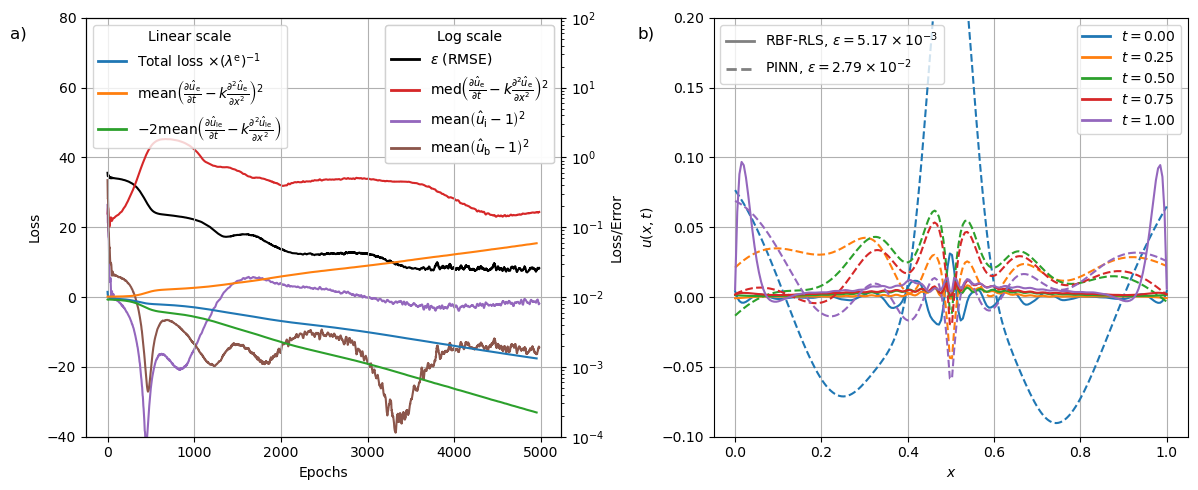

In [26]:

t_snapshots = np.linspace(0, 1, 5)+10**-6

fig,axes  = plt.subplots(ncols = 2,figsize=(12, 5))

colors = list(mcolors.TABLEAU_COLORS.values())

axes[0].plot(np.convolve(np.array(loss_hist)/10**best_params[2],np.ones(50)/50, mode = 'valid'), c = colors[0])
axes[0].plot(np.convolve(np.array(losses_hist)[:,0],np.ones(50)/50, mode = 'valid'), c = colors[1])
axes[0].plot(np.convolve(np.array(losses_hist)[:,2],np.ones(50)/50, mode = 'valid'), color = colors[2])
axes[0].legend()
# axes[0].grid()
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')

linear_loss_handles = [Line2D([0], [0], color=colors[0], lw=2, label=r'Total loss $\times(\lambda^{\text{e}})^{-1}$'),
                       Line2D([0], [0], color=colors[1], lw=2, label=r'$\mathrm{mean}\left(\frac{\partial \hat{u}_{\text{e}}}{\partial t} - k \frac{\partial^2 \hat{u}_{\text{e}}}{\partial x^2}\right)^2$'),
                       Line2D([0], [0], color=colors[2], lw=2, label=r'$-2\mathrm{mean}\left(\frac{\partial \hat{u}_{\text{le}}}{\partial t} - k \frac{\partial^2 \hat{u}_{\text{le}}}{\partial x^2}\right)$')]
legend_linear_loss = axes[0].legend(
    handles=linear_loss_handles,
    title = 'Linear scale',
    loc='upper left',
    frameon=True
)
axes[0].add_artist(legend_linear_loss)

ax_twin = axes[0].twinx()

# ---- Log-scale alignment ----
ax_twin.set_yscale('log')

# Define the visible log range (example: 1e-5 to 1e0 → 5 orders)
ymin, ymax = 1e-4, 1e2
ax_twin.set_ylim(ymin, ymax)
axes[0].set_ylim(ymin, ymax)

# Use identical log tick locators
log_locator = LogLocator(base=10, numticks=7)

ax_twin.yaxis.set_major_locator(log_locator)


axes[0].set_yticks([-40,-20,0,20,40,60,80])
axes[0].set_ylim(-40,80)


ax_twin.semilogy(np.convolve(eval_hist,np.ones(20)/20, mode = 'valid'), label = 'IC and BC enforced by loss, ', c= 'k')
for ii,i in enumerate([1,3,4]):
    if i == 4:
        ax_twin.semilogy(np.convolve(np.array(losses_hist)[:,i]+np.array(losses_hist)[:,i+1],np.ones(20)/20, mode = 'valid'), color = colors[ii+3])
    else:
        ax_twin.semilogy(np.convolve(np.array(losses_hist)[:,i],np.ones(20)/20, mode = 'valid'), color = colors[ii+3])
ax_twin.grid()
ax_twin.set_xlabel('Epochs')
ax_twin.set_ylabel('Loss/Error')


log_losses_labels = [r'$\mathrm{med}\left(\frac{\partial \hat{u}_{\text{e}}}{\partial t} - k \frac{\partial^2 \hat{u}_{\text{e}}}{\partial x^2}\right)^2$',
                    r'$\mathrm{mean}\left(\hat{u}_{\text{i}}-1\right)^2$',
                    r'$\mathrm{mean}\left(\hat{u}_{\text{b}}-1\right)^2$']
log_losses_handles = [Line2D([0], [0], color='k', lw=2, label=r'$\varepsilon$ (RMSE)')]+[Line2D([0], [0], color=colors[i+3], lw=2, label=n) for i,n in enumerate(log_losses_labels)]
legend_log_losses_or_errors = axes[0].legend(
    handles=log_losses_handles,
    title = 'Log scale',
    loc='upper right',
    frameon=True
)
axes[0].add_artist(legend_log_losses_or_errors)

axes[0].set_zorder(1)  
ax_twin.set_zorder(0)
axes[0].set_facecolor('none') 
# Horizontal (y) grid from log axis
ax_twin.grid(True, axis='y', which='major')

# Vertical (x) grid
axes[0].grid(True, axis='x', which='major')


time_handles = []

from scipy import special
def h_analyt_np(x_, t_, k_, Q_, x_star_):
    ns=np.arange(-10,11)
    total=1
    for n in ns:
        total-=(Q_/(2*k_)*abs(x_-(2*n+x_star_))*special.erfc(abs(x_-(2*n+x_star_))/(4*k_*t_)**(1/2))
                -Q_*(t_/(k_*np.pi))**(1/2)*np.exp(-(x_-(2*n+x_star_))**(2)/(4*k_*t_))
                -Q_/(2*k_)*abs(x_-(2*n-x_star_))*special.erfc(abs(x_-(2*n-x_star_))/(4*k_*t_)**(1/2))
                +Q_*(t_/(k_*np.pi))**(1/2)*np.exp(-(x_-(2*n-x_star_))**(2)/(4*k_*t_))
               )
    return total
    
u_ref = h_analyt_np(*np.meshgrid(np.linspace(0,1,Nx_eval),np.linspace(0,1,Nt_eval)), k, Q, 0.5)

u_pred = model(Xf_t, Tf_t).detach().cpu().numpy().reshape(X_eval.shape)

for i, t_snap in enumerate(t_snapshots):
    idx = np.abs(t_eval - t_snap).argmin()
    # ---------- PINN (final) ----------
    # with torch.no_grad():
    #     model.load_state_dict(model_snapshots[-1])
    #     model.to(device)
    #     model.eval()
    #     
    axes[1].plot(np.linspace(0,1,Nx_eval),u_RBF[idx]-u_ref[idx],color=colors[i],linestyle='solid')
    
    axes[1].plot(np.linspace(0,1,Nx_eval),u_pred[idx]-u_ref[idx],color=colors[i],linestyle='dashed')

    time_handles.append(Line2D([0], [0],color=colors[i],lw=2,linestyle='solid',label=fr'$t = {t_snap:.2f}$'))

RMSE_RBF = np.sqrt(np.sum((u_RBF-u_ref)**2)/u_RBF.size)
RMSE_RBF_mant = RMSE_RBF/10**(int(np.log10(RMSE_RBF))-1)
RMSE_RBF_exp = int(np.log10(RMSE_RBF))-1
RMSE_PINN = np.sqrt(np.sum((u_pred-u_ref)**2)/u_pred.size)
RMSE_PINN_mant = RMSE_PINN/10**(int(np.log10(RMSE_PINN))-1)
RMSE_PINN_exp = int(np.log10(RMSE_PINN))-1

# ---------- Legends ----------
legend_time = axes[1].legend(
    handles=time_handles,
    loc='upper right',
    frameon=True
)

method_handles = [
    Line2D([0], [0], color='gray', lw=2, linestyle='solid', label=fr'RBF-RLS, $\varepsilon = {RMSE_RBF_mant:.2f}\times 10^{{{RMSE_RBF_exp}}}$'),
    Line2D([0], [0], color='gray', lw=2, linestyle='dashed', label=fr'PINN, $\varepsilon = {RMSE_PINN_mant:.2f}\times 10^{{{RMSE_PINN_exp}}}$'),
]

legend_method = axes[1].legend(
    handles=method_handles,
    loc='upper left',
    frameon=True
)

axes[1].add_artist(legend_time)

# ---------- Formatting ----------
axes[1].set_xlabel(r'$x$')
axes[1].set_ylabel(r'$u(x,t)$')
axes[1].grid(True)
axes[1].set_ylim(-0.10,0.2)

labels = ['a)', 'b)', 'c)', 'd)']

for ax, label in zip(axes.flat, labels):
    ax.text(
        -0.16, 0.98, label,
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left'
    )



plt.tight_layout()
plt.show()



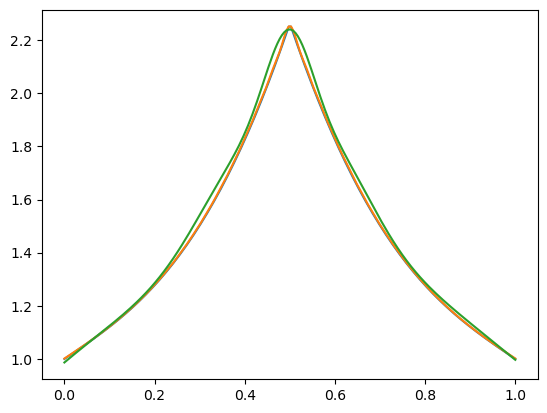

In [17]:
idx = -100
plt.plot(np.linspace(0,1,Nx_eval),u_ref[idx])
plt.plot(np.linspace(0,1,Nx_eval),u_RBF[idx])
plt.plot(np.linspace(0,1,Nx_eval),u_pred[idx])